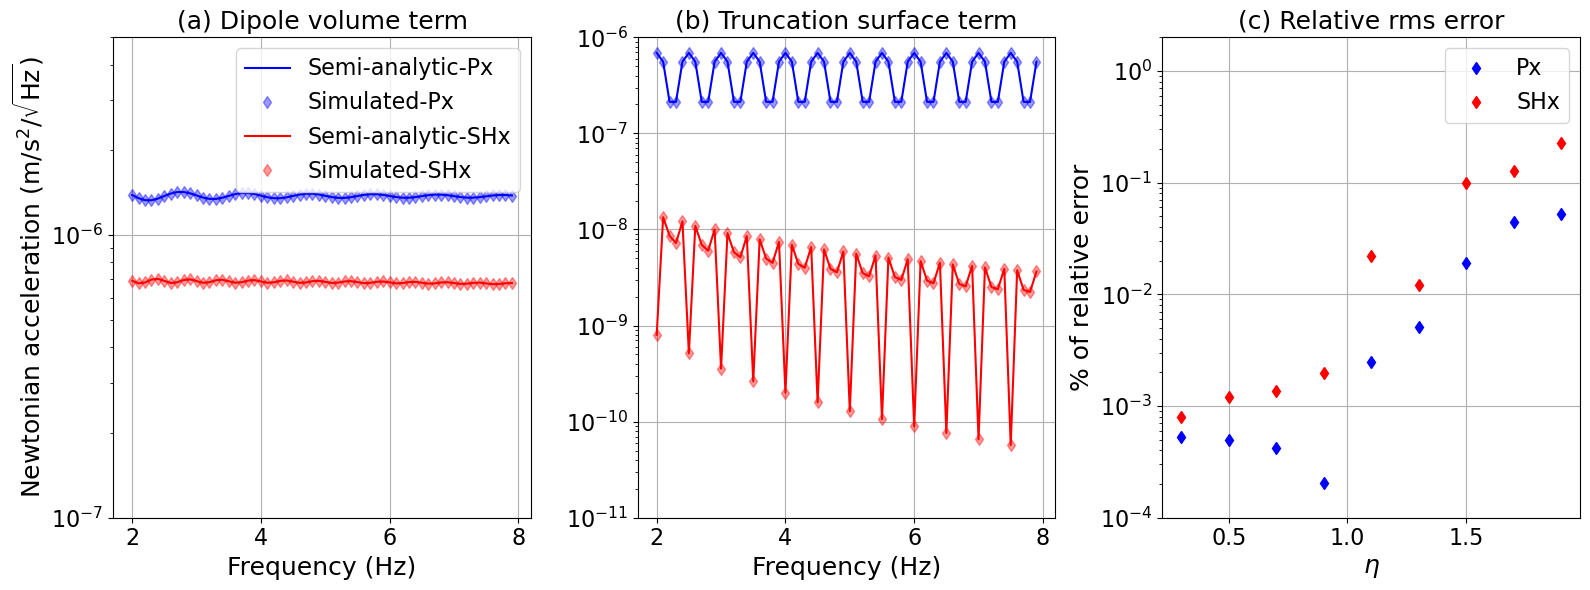

In [7]:
# this script plots the fit between the numrical and semi-analytic
# estimates of the Newtonian acceleration experienced by a test-mass
# inside a spherical or cuboidal cavity hosted in either full-space
# half-space geology with plane body waves propagating
# Since this is for validation, we consider only single plane P- or S-waves

import matplotlib.pyplot as plt
import scipy.constants as const
import numpy as np
import os
from modules import configLoader
from modules import bodyPSNN
from modules import plotUtils

# in the initial case we will consider only the spherical cavity hosted in
# full-space
configFile="/home/koley/CavityResults/EtaTestConfig/configParseSphFullSpaceBodyHomo.ini"
figPathSph = '/home/koley/CavityResults/AllTutOut/EtaTest/Figures/sphFullSpaceBodyHomoEtaTest.pdf'
radiusUse = 20.0

config = configLoader.load_config(configFile)
wType = ['Px','SHx']
etaAll = np.arange(0.3,2.0,0.2)
etaOne = 0.5 # specific eta for which fits are shown
G = const.G
rho = config.rho[0]
vS = config.vS[0]
vP = config.vP[0]
rho = config.rho[0]

L = 4000.0
sphere_radius = 20

xi0 = 1.0
# depth of cavity center below the surface
cav_depth = 4000.0
# cavity center in global coordinates
cav_center = np.array([0.0, 0.0, L - cav_depth])
outer_bounds = (-L, L,-L, L,-L, L)

# test mass at cavity center
tm = cav_center.copy()
tm_shift = np.array([0.0, 0.0, 0.0])   # example: no shift
tm = cav_center + tm_shift

# make the first two plots showing the dipole and the truncation surface
# integrations
plotUtils.set_plot_style(style="large")
fig,ax = plt.subplots(1,3,figsize=(16,6))

for wNo in range(0,len(wType)):
    
    nnFName = 'NNFullRea0'+'Eta' + f"{etaOne:.1f}" + wType[wNo] + 'Rad' + str(20.0) + '.npz'
    data = np.load(os.path.join(config.outDispPathRea,nnFName))

    Iblock = data["IBlockTot"]
    Ivert  = data["IVertFaceTot"]
    Ihor   = data["IHorFaceTot"]
    Itot   = data["ITot"]
    freqOut = data["freqOut"]

    if(wType[wNo]=='SHy'):
        pieces = [bodyPSNN.SH_y_x_sphere_all_components_shifted(f,vS,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                      sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                      for f in freqOut]
        compPlot = 0
    elif(wType[wNo]=='SHx'):
        pieces = [bodyPSNN.SH_x_y_sphere_all_components_shifted(f,vS,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                            sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                            for f in freqOut]
        compPlot = 1
    elif(wType[wNo]=='SV'):
        pieces = [bodyPSNN.SV_x_z_sphere_all_components_shifted(f,vS,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                            sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                            for f in freqOut]
        compPlot = 2
    elif(wType[wNo]=='Px'):
        pieces = [bodyPSNN.P_x_sphere_all_components_shifted(f,vP,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                         sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                         for f in freqOut]
        compPlot = 0
    else:
        pieces = [bodyPSNN.P_z_sphere_all_components_shifted(f,vP,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                         sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                         for f in freqOut]
        compPlot = 2

    H_bulk  = np.array([p[0] for p in pieces])   # shape (nFreq, 3)
    H_vert  = np.array([p[1] for p in pieces])
    H_hor   = np.array([p[2] for p in pieces])
    H_total = np.array([p[3] for p in pieces])

    A_bulk  = G*rho*xi0*H_bulk
    A_vert  = G*rho*xi0*H_vert
    A_hor = G*rho*xi0*H_hor
    A_total = G*rho*xi0*H_total

    if(wType[wNo] == 'Px'):
        # plot the dipole contribution
        ax[0].plot(freqOut, np.abs(A_bulk[:,compPlot]),'b',label='Semi-analytic-Px')
        ax[0].plot(freqOut, np.abs(Iblock[:,compPlot,0]),'bd',alpha=0.4,label='Simulated-Px')
        ax[0].set_ylabel(r'Newtonian acceleration ($\mathrm{m/s}^2/\sqrt{\mathrm{Hz}}$)')
        ax[0].set_xlabel('Frequency (Hz)')
        ax[0].set_title('(a) Dipole volume term')

        # plot the surface contribution
        ax[1].plot(freqOut, np.abs(A_vert[:,compPlot]),'b',label='Semi-analytic-Px')
        ax[1].plot(freqOut, np.abs(Ivert[:,compPlot,0]),'bd',alpha=0.4,label='Simulated-Px')
        #ax[0].set_ylabel(r'Newtonian acceleration ($\mathrm{m/s}^2/\sqrt{\mathrm{Hz}}$)')
        ax[1].set_xlabel('Frequency (Hz)')
        ax[1].set_title('(b) Truncation surface term')

    if(wType[wNo] == 'SHx'):
        # plot the dipole contribution
        ax[0].plot(freqOut, np.abs(A_bulk[:,compPlot]),'r',label='Semi-analytic-SHx')
        ax[0].plot(freqOut, np.abs(Iblock[:,compPlot,0]),'rd',alpha=0.4,label='Simulated-SHx')
    
        # plot the surface contribution
        ax[1].plot(freqOut, np.abs(A_vert[:,compPlot]),'r',label='Semi-analytic-SHx')
        ax[1].plot(freqOut, np.abs(Ivert[:,compPlot,0]),'rd',alpha=0.4,label='Simulated-SHx')
                       
relErrPrct = np.zeros((len(etaAll),len(wType)))
for wNo in range(0,len(wType)):
    for etaNo in range(0,len(etaAll)):
        nnFName = 'NNFullRea0'+'Eta' + f"{etaAll[etaNo]:.1f}" + wType[wNo] + 'Rad' + str(20.0) + '.npz'
        data = np.load(os.path.join(config.outDispPathRea,nnFName))

        Iblock = data["IBlockTot"]
        Ivert  = data["IVertFaceTot"]
        Ihor   = data["IHorFaceTot"]
        Itot   = data["ITot"]
        freqOut = data["freqOut"]

        if(wType[wNo]=='SHy'):
            pieces = [bodyPSNN.SH_y_x_sphere_all_components_shifted(f,vS,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                      sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                      for f in freqOut]
            compPlot = 0
        elif(wType[wNo]=='SHx'):
            pieces = [bodyPSNN.SH_x_y_sphere_all_components_shifted(f,vS,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                            sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                            for f in freqOut]
            compPlot = 1
        elif(wType[wNo]=='SV'):
            pieces = [bodyPSNN.SV_x_z_sphere_all_components_shifted(f,vS,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                            sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                            for f in freqOut]
            compPlot = 2
        elif(wType[wNo]=='Px'):
            pieces = [bodyPSNN.P_x_sphere_all_components_shifted(f,vP,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                         sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                         for f in freqOut]
            compPlot = 0
        else:
            pieces = [bodyPSNN.P_z_sphere_all_components_shifted(f,vP,outer_bounds=outer_bounds,sphere_center=cav_center,
                                                         sphere_radius=sphere_radius,tm=tm,n_mu=64,n_phi=128,n_r=64,)
                                                         for f in freqOut]
            compPlot = 2

        H_bulk  = np.array([p[0] for p in pieces])   # shape (nFreq, 3)
        H_vert  = np.array([p[1] for p in pieces])
        H_hor   = np.array([p[2] for p in pieces])
        H_total = np.array([p[3] for p in pieces])

        A_bulk  = G*rho*xi0*H_bulk
        A_vert  = G*rho*xi0*H_vert
        A_hor = G*rho*xi0*H_hor
        A_total = G*rho*xi0*H_total

        # get the error in the total estimate
        errOut = np.abs(A_total[:,compPlot] - Itot[:,compPlot,0])
        relErrPrct[etaNo,wNo] = np.sqrt(np.sum(errOut**2)/(np.sum(np.abs(A_total[:,compPlot]))**2))*100


ax[0].set_yscale('log')
ax[0].grid()
ax[0].legend()
ax[0].set_ylim(10**-7,5*10**-6)

ax[1].set_ylim(10**-11,10**-6)
ax[1].set_yscale('log')
ax[1].grid()


ax[2].semilogy(etaAll,relErrPrct[:,0],'bd',label='Px')
ax[2].semilogy(etaAll,relErrPrct[:,1],'rd',label='SHx')
ax[2].set_xlabel(r'$\eta$')
ax[2].set_ylabel('% of relative error')
ax[2].set_title('(c) Relative rms error')
ax[2].grid()
ax[2].set_ylim(10**-4,2*10**0)
ax[2].legend()
plt.tight_layout()

fig.savefig(figPathSph, bbox_inches="tight",transparent=False,metadata={"Creator": "Python/Matplotlib"})


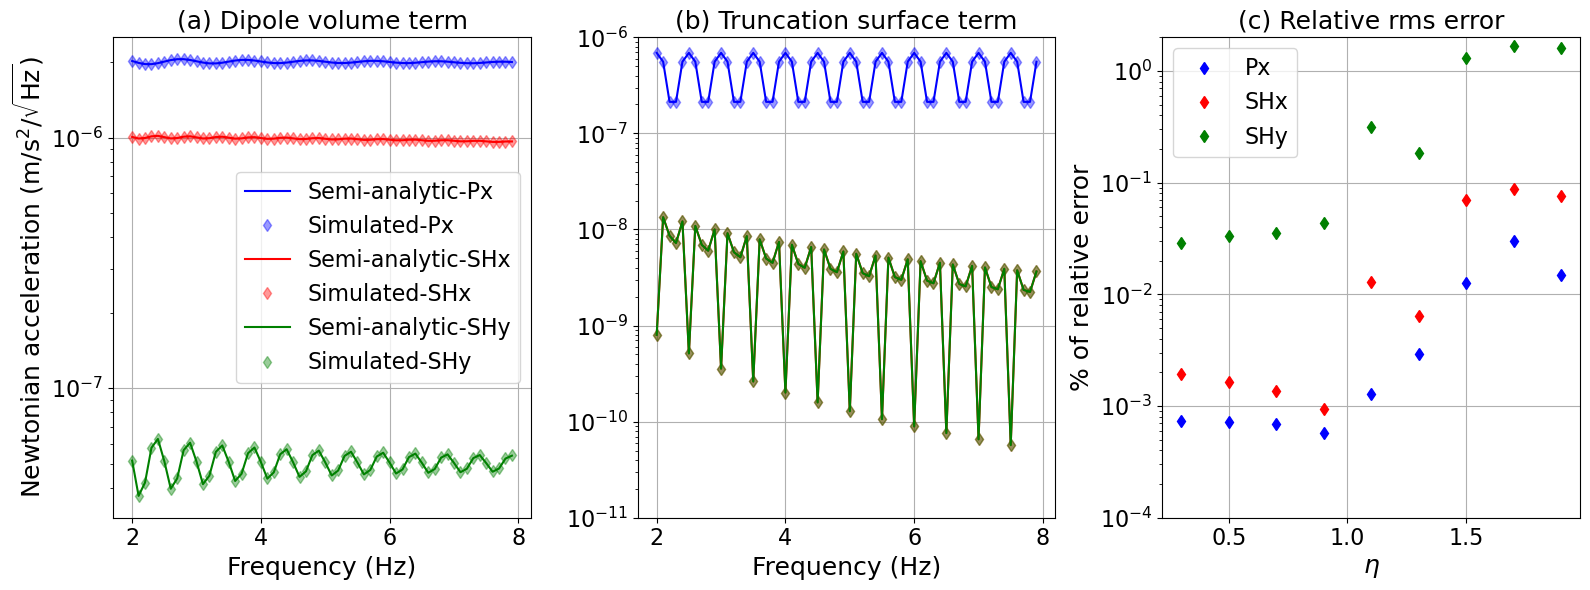

In [8]:
# perform similar analysis for 100, 20, 20 m long cuboid
configFile="/home/koley/CavityResults/EtaTestConfig/configParseCubFullSpaceBodyHomo.ini"
config = configLoader.load_config(configFile)
figPathCub = '/home/koley/CavityResults/AllTutOut/EtaTest/Figures/cubFullSpaceBodyHomoEtaTest.pdf'

wType = ['Px','SHx','SHy']
etaAll = np.arange(0.3,2.0,0.2)
G = const.G
rho = config.rho[0]
vS = config.vS[0]
vP = config.vP[0]
rho = config.rho[0]

L = 4000.0
# cavity half-lengths
a = 50.0
b = 10.0
c = 10.0
xi0 = 1.0
lengthUse = 2*a
cav_depth = 4000.0
# cavity center in global coordinates
cav_center = np.array([0.0, 0.0, L - cav_depth])
outer_bounds = (-L, L,-L, L,-L, L)
cavity_bounds = (
    cav_center[0] - a, cav_center[0] + a,
    cav_center[1] - b, cav_center[1] + b,
    cav_center[2] - c, cav_center[2] + c,
)
# test mass at cavity center
tm = cav_center.copy()
tm_shift = np.array([0.0, 0.0, 0.0])   # example: no shift
tm = cav_center + tm_shift

# make the first two plots showing the dipole and the truncation surface
# integrations
plotUtils.set_plot_style(style="large")
fig,ax = plt.subplots(1,3,figsize=(16,6))

for wNo in range(0,len(wType)):
    
    nnFName = 'NNFullRea0'+'Eta' + f"{etaOne:.1f}" + wType[wNo] + 'Rad' + str(100.0) + '.npz'
    data = np.load(os.path.join(config.outDispPathRea,nnFName))

    Iblock = data["IBlockTot"]
    Ivert  = data["IVertFaceTot"]
    Ihor   = data["IHorFaceTot"]
    Itot   = data["ITot"]
    freqOut = data["freqOut"]

    if(wType[wNo] == 'Px'):
        pieces = [bodyPSNN.P_x_all_components_shifted(f,vP,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                      tm=tm,)
                                                      for f in freqOut]
        compPlot = 0
    
    elif(wType[wNo] == 'Pz'):
        pieces = [bodyPSNN.P_z_all_components_shifted(f,vP,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                      tm=tm,)
                                                      for f in freqOut]
        compPlot = 2
    
    elif(wType[wNo]=='SHy'):
        pieces = [bodyPSNN.SH_y_x_all_components_shifted(f,vS,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                         tm=tm,)
                                                         for f in freqOut]
        compPlot = 0
    elif(wType[wNo] == 'SHx'):
        pieces = [bodyPSNN.SH_x_y_all_components_shifted(f,vS,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                         tm=tm,)
                                                         for f in freqOut]
        compPlot = 1
    
    else:
        pieces = [bodyPSNN.SV_x_z_all_components_shifted(f,vS,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                         tm=tm,)
                                                         for f in freqOut]
        compPlot = 2

    H_bulk  = np.array([p[0] for p in pieces])   # shape (nFreq, 3)
    H_vert  = np.array([p[1] for p in pieces])
    H_hor   = np.array([p[2] for p in pieces])
    H_total = np.array([p[3] for p in pieces])

    A_bulk  = G*rho*xi0*H_bulk
    A_vert  = G*rho*xi0*H_vert
    A_hor = G*rho*xi0*H_hor
    A_total = G*rho*xi0*H_total

    if(wType[wNo] == 'Px'):
        # plot the dipole contribution
        ax[0].plot(freqOut, np.abs(A_bulk[:,compPlot]),'b',label='Semi-analytic-Px')
        ax[0].plot(freqOut, np.abs(Iblock[:,compPlot,0]),'bd',alpha=0.4,label='Simulated-Px')
        ax[0].set_ylabel(r'Newtonian acceleration ($\mathrm{m/s}^2/\sqrt{\mathrm{Hz}}$)')
        ax[0].set_xlabel('Frequency (Hz)')
        ax[0].set_title('(a) Dipole volume term')

        # plot the surface contribution
        ax[1].plot(freqOut, np.abs(A_vert[:,compPlot]),'b',label='Semi-analytic-Px')
        ax[1].plot(freqOut, np.abs(Ivert[:,compPlot,0]),'bd',alpha=0.4,label='Simulated-Px')
        #ax[0].set_ylabel(r'Newtonian acceleration ($\mathrm{m/s}^2/\sqrt{\mathrm{Hz}}$)')
        ax[1].set_xlabel('Frequency (Hz)')
        ax[1].set_title('(b) Truncation surface term')

    if(wType[wNo] == 'SHx'):
        # plot the dipole contribution
        ax[0].plot(freqOut, np.abs(A_bulk[:,compPlot]),'r',label='Semi-analytic-SHx')
        ax[0].plot(freqOut, np.abs(Iblock[:,compPlot,0]),'rd',alpha=0.4,label='Simulated-SHx')
    
        # plot the surface contribution
        ax[1].plot(freqOut, np.abs(A_vert[:,compPlot]),'r',label='Semi-analytic-SHx')
        ax[1].plot(freqOut, np.abs(Ivert[:,compPlot,0]),'rd',alpha=0.4,label='Simulated-SHx')

    if(wType[wNo] == 'SHy'):
        # plot the dipole contribution
        ax[0].plot(freqOut, np.abs(A_bulk[:,compPlot]),'g',label='Semi-analytic-SHy')
        ax[0].plot(freqOut, np.abs(Iblock[:,compPlot,0]),'gd',alpha=0.4,label='Simulated-SHy')
        
        # plot the surface contribution
        ax[1].plot(freqOut, np.abs(A_vert[:,compPlot]),'g',label='Semi-analytic-SHy')
        ax[1].plot(freqOut, np.abs(Ivert[:,compPlot,0]),'gd',alpha=0.4,label='Simulated-SHy')

relErrPrctCuboid = np.zeros((len(etaAll),len(wType)))

for wNo in range(0,len(wType)):
    for etaNo in range(0,len(etaAll)):

        nnFName = 'NNFullRea0'+'Eta' + f"{etaAll[etaNo]:.1f}" + wType[wNo] + 'Rad' + f"{lengthUse:.1f}" + '.npz'
        data = np.load(os.path.join(config.outDispPathRea,nnFName))

        Iblock = data["IBlockTot"]
        Ivert  = data["IVertFaceTot"]
        Ihor   = data["IHorFaceTot"]
        Itot   = data["ITot"]   
        freqOut = data["freqOut"]

        if(wType[wNo] == 'Px'):
            pieces = [bodyPSNN.P_x_all_components_shifted(f,vP,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                  tm=tm,)
                                                  for f in freqOut]
            compPlot = 0

        elif(wType[wNo] == 'Pz'):
            pieces = [bodyPSNN.P_z_all_components_shifted(f,vP,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                  tm=tm,)
                                                  for f in freqOut]
            compPlot = 2

        elif(wType[wNo]=='SHy'):
            pieces = [bodyPSNN.SH_y_x_all_components_shifted(f,vS,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                     tm=tm,)
                                                     for f in freqOut]
            compPlot = 0
        elif(wType[wNo] == 'SHx'):
            pieces = [bodyPSNN.SH_x_y_all_components_shifted(f,vS,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                     tm=tm,)
                                                     for f in freqOut]
            compPlot = 1

        else:
            pieces = [bodyPSNN.SV_x_z_all_components_shifted(f,vS,outer_bounds=outer_bounds,cavity_bounds=cavity_bounds,
                                                     tm=tm,)
                                                     for f in freqOut]
            compPlot = 2

        H_bulk  = np.array([p[0] for p in pieces])   # shape (nFreq, 3)
        H_vert  = np.array([p[1] for p in pieces])
        H_hor   = np.array([p[2] for p in pieces])
        H_total = np.array([p[3] for p in pieces])

        A_bulk  = G*rho*xi0*H_bulk
        A_vert  = G*rho*xi0*H_vert
        A_hor = G*rho*xi0*H_hor
        A_total = G*rho*xi0*H_total

        # get the error in the total estimate
        errOut = np.abs(A_total[:,compPlot] - Itot[:,compPlot,0])
        relErrPrctCuboid[etaNo,wNo] = np.sqrt(np.sum(errOut**2)/(np.sum(np.abs(A_total[:,compPlot]))**2))*100

ax[0].set_yscale('log')
ax[0].grid()
ax[0].legend()
#ax[0].set_ylim(10**-7,5*10**-6)

ax[1].set_ylim(10**-11,10**-6)
ax[1].set_yscale('log')
ax[1].grid()

      
ax[2].semilogy(etaAll,relErrPrctCuboid[:,0],'bd',label='Px')
ax[2].semilogy(etaAll,relErrPrctCuboid[:,1],'rd',label='SHx')
ax[2].semilogy(etaAll,relErrPrctCuboid[:,2],'gd',label='SHy')
ax[2].set_xlabel(r'$\eta$')
ax[2].set_ylabel('% of relative error')
ax[2].set_title('(c) Relative rms error')
ax[2].grid()
ax[2].set_ylim(10**-4,2*10**0)
ax[2].legend()
plt.tight_layout()

fig.savefig(figPathCub, bbox_inches="tight",transparent=False,metadata={"Creator": "Python/Matplotlib"})
